# 01 · Objetivo (i): requisitos de experiência prévia e formação

> *"Identificar os requisitos de experiência prévia e formação declarados nos anúncios selecionados."* (Seção 1.3, objetivo i)

**Perguntas deste notebook**
1. Que parcela dos anúncios menciona exigência de experiência, e de que tipo (tempo mínimo, experiência prévia explícita, experiência em tecnologia)?
2. Como isso muda entre **Estágio** e **Júnior**, e entre os grupos de área?
3. A experiência é **obrigatória** ou apenas **desejável**? Com que frequência o anúncio diz que **não** a exige?
4. Que tempo mínimo é pedido nos anúncios de Júnior?
5. Que formação aparece (cursando, superior completo, técnico, etc.)?

**Ligação com a literatura:** Westby et al. (2026) observam aumento da experiência média exigida *dentro* dos mesmos títulos; Dobslaw et al. (2023) discutem o "paradoxo da experiência"; Lopes et al. (2024) e Brasscom/PROA (2025) tratam a experiência como barreira de entrada.

> **Cuidado de leitura.** Este é um retrato de um único momento. Ele **não mostra aumento** da exigência de experiência; só descreve o nível atual e permite comparar Estágio com Júnior.
> A detecção é feita por expressões regulares (ver `analise_lib.py`) e precisa de validação por leitura manual.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
import analise_lib as L
L.estilo()
pd.set_option("display.max_colwidth", None, "display.width", 220)
df = L.carregar()
ej = df[df["nivel"].isin(L.NIVEIS_PRINCIPAIS)].copy()
print(f"Base: {len(df):,} anúncios | Estágio + Júnior: {len(ej):,}")

Base: 9,964 anúncios | Estágio + Júnior: 9,707


## 1. Tipos de exigência de experiência

Cada anúncio recebe o **tipo mais forte** de menção encontrado:
1. **Tempo mínimo declarado** (ex.: *"2 anos de experiência"*)
2. **Experiência prévia explícita** (ex.: *"experiência prévia / comprovada / na área"*)
3. **Experiência em/com tecnologia** (ex.: *"experiência com Python"*), o critério mais fraco e mais ambíguo
4. **Sem menção**

Excluídas as menções que falam da empresa, do usuário/cliente ou do que o estágio *oferece* (*"ganhar experiência"*).

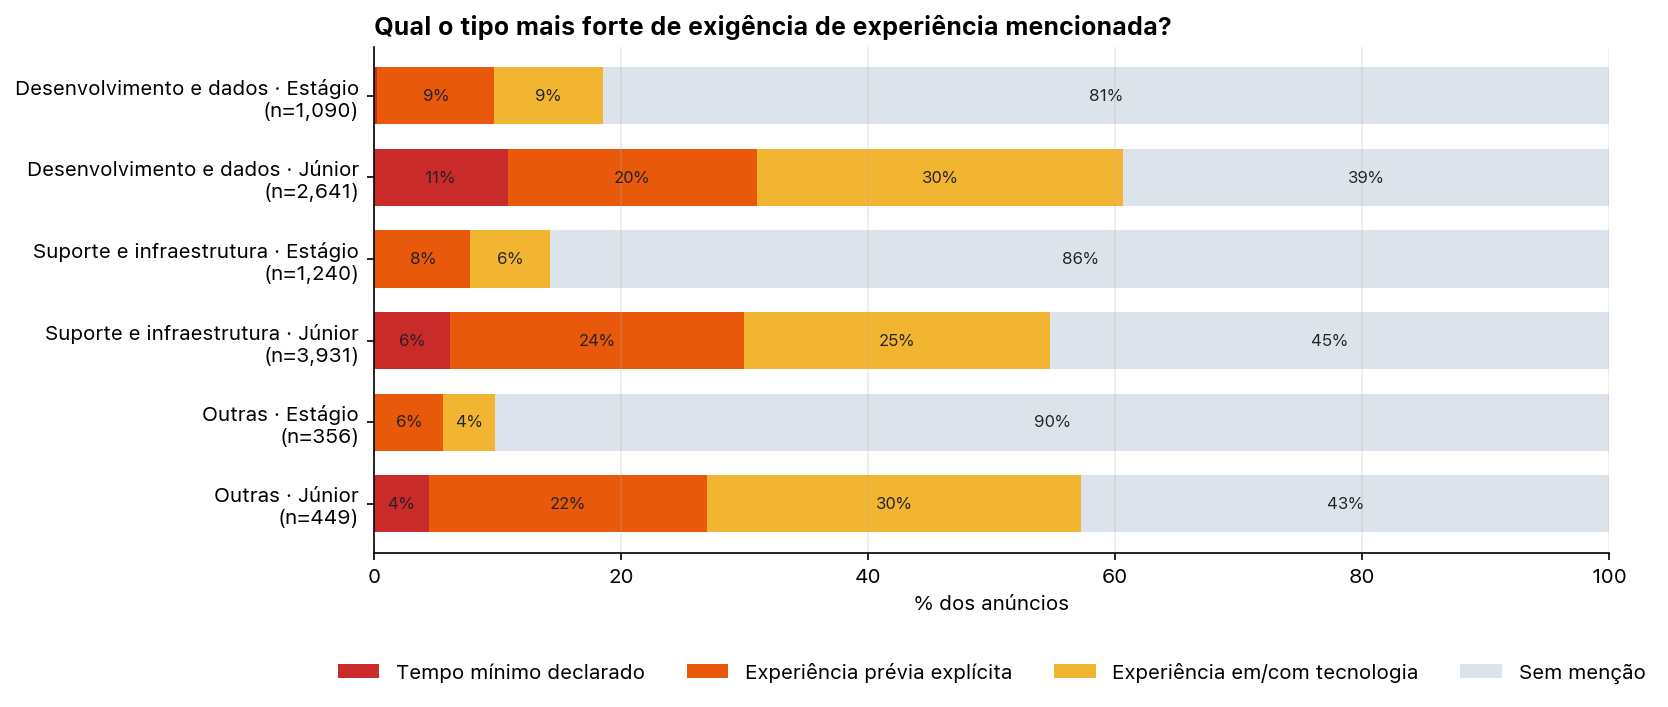

In [2]:
tipos = ["Tempo mínimo declarado", "Experiência prévia explícita", "Experiência em/com tecnologia", "Sem menção"]
ej["tipo_exp"] = np.select([ej.exp_tempo, ej.exp_previa, ej.exp_tecnologia], tipos[:3], default=tipos[3])
t = ej.groupby(["grupo", "nivel", "tipo_exp"]).size().unstack(fill_value=0).reindex(columns=tipos, fill_value=0)
n = t.sum(axis=1)
p = t.div(n, axis=0) * 100
p.index = [f"{g} · {nv}\n(n={n[(g, nv)]:,})" for g, nv in p.index]
ordem = [f"{g} · {nv}\n(n={n[(g, nv)]:,})" for g in L.ORDEM_GRUPOS for nv in L.NIVEIS_PRINCIPAIS]
p = p.loc[ordem]
cores = ["#C92A2A", "#E8590C", "#F2B531", "#DDE3EA"]
fig, ax = plt.subplots(figsize=(11, 4.6))
p.iloc[::-1].plot(kind="barh", stacked=True, ax=ax, color=cores, width=.7)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0f}%" if v >= 4 else "" for v in c.datavalues], label_type="center", fontsize=8, color="#222")
ax.set_xlabel("% dos anúncios"); ax.set_title("Qual o tipo mais forte de exigência de experiência mencionada?")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(.5, -.18)); ax.grid(axis="y", visible=False); ax.set_xlim(0, 100)
L.salvar(fig, "01_tipos_experiencia"); plt.show()

## 2. Parcela com qualquer menção a experiência, por nível e grupo (com IC 95%)

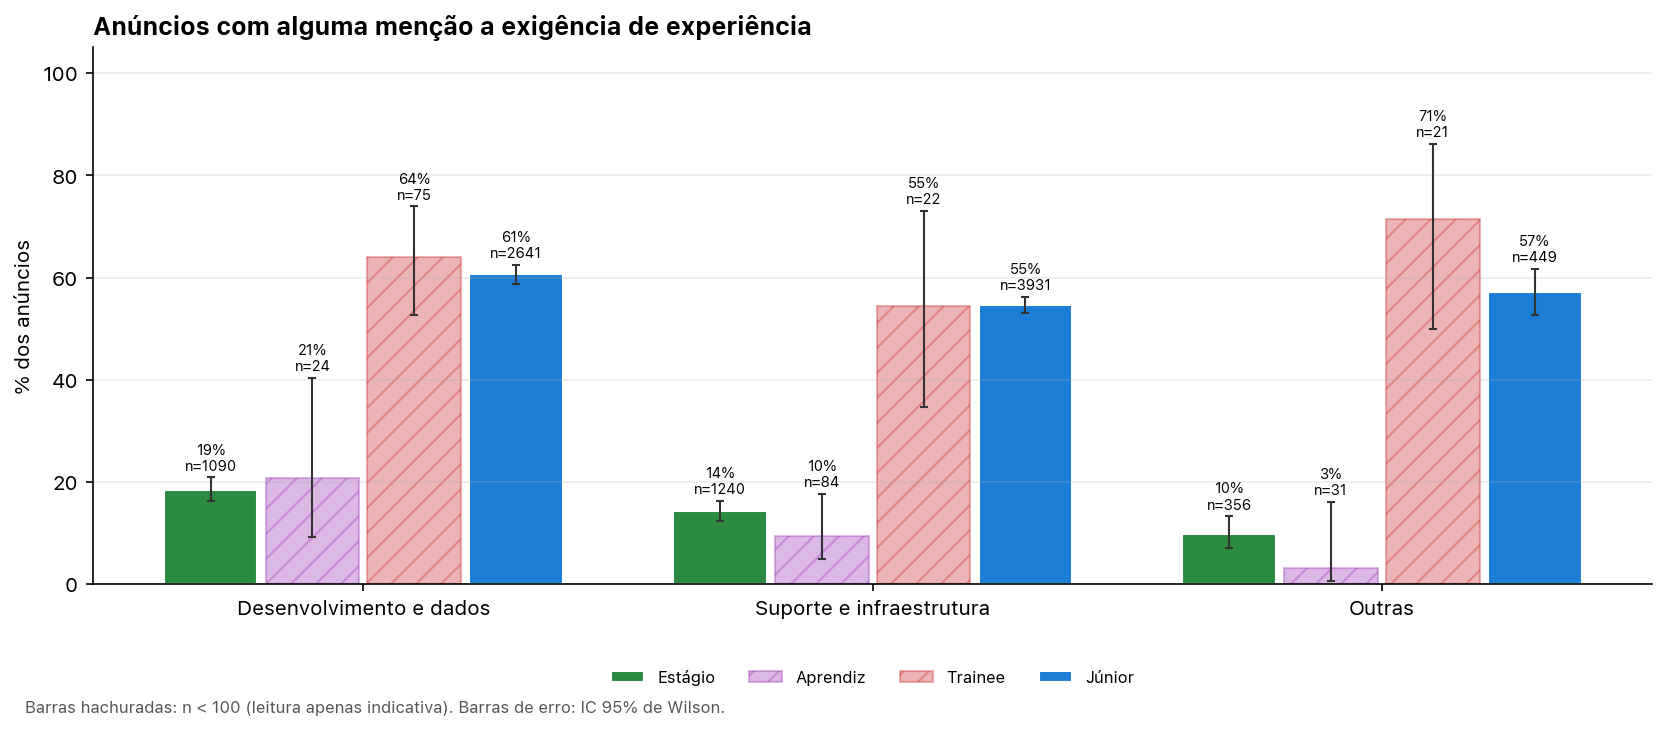

In [3]:
tab = L.tabela_prop(df, "exp_qualquer", ["grupo", "nivel"])
fig, ax = plt.subplots(figsize=(11, 4.6))
L.barras_prop(ax, tab, "grupo", "nivel", L.ORDEM_GRUPOS, L.ORDEM_NIVEIS, L.PALETA_NIVEL)
ax.set_title("Anúncios com alguma menção a exigência de experiência"); L.nota_n_pequeno(fig)
L.salvar(fig, "01_experiencia_qualquer"); plt.show()

## 3. Obrigatória × desejável, e anúncios que dizem **não** exigir experiência

Uma menção é considerada **desejável** se aparece sob um título de "diferenciais/desejáveis" ou perto de termos como
*"desejável", "diferencial", "será um plus"*. Esta é uma heurística e deve ser conferida por amostragem (seção 6).

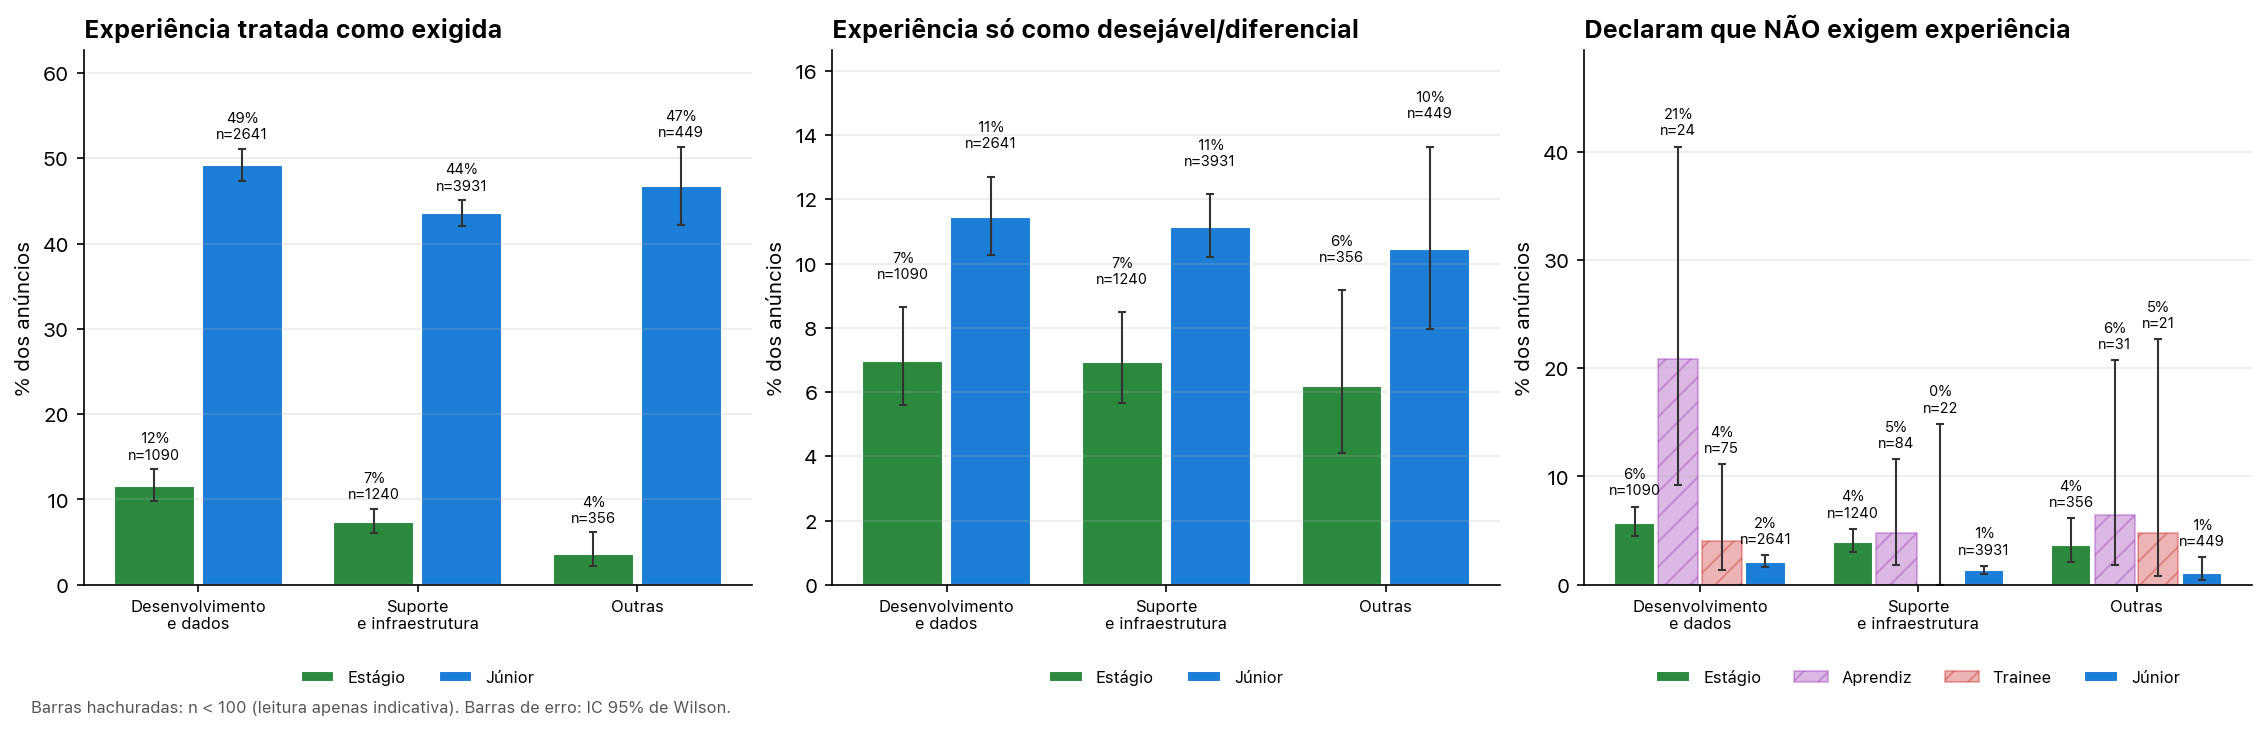

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
ob = L.tabela_prop(df, "exp_obrigatoria", ["grupo", "nivel"])
L.barras_prop(axes[0], ob, "grupo", "nivel", L.ORDEM_GRUPOS, ["Estágio", "Júnior"], L.PALETA_NIVEL)
axes[0].set_title("Experiência tratada como exigida"); axes[0].set_xticklabels([g.replace(" e ", "\ne ") for g in L.ORDEM_GRUPOS], fontsize=8)
de = L.tabela_prop(df, "exp_so_desejavel", ["grupo", "nivel"])
L.barras_prop(axes[1], de, "grupo", "nivel", L.ORDEM_GRUPOS, ["Estágio", "Júnior"], L.PALETA_NIVEL)
axes[1].set_title("Experiência só como desejável/diferencial"); axes[1].set_xticklabels([g.replace(" e ", "\ne ") for g in L.ORDEM_GRUPOS], fontsize=8)
ne = L.tabela_prop(df, "exp_nao_exige", ["grupo", "nivel"])
L.barras_prop(axes[2], ne, "grupo", "nivel", L.ORDEM_GRUPOS, L.ORDEM_NIVEIS, L.PALETA_NIVEL)
axes[2].set_title("Declaram que NÃO exigem experiência"); axes[2].set_xticklabels([g.replace(" e ", "\ne ") for g in L.ORDEM_GRUPOS], fontsize=8)
L.nota_n_pequeno(fig); L.salvar(fig, "01_obrigatoria_desejavel_naoexige"); plt.show()

## 4. Tempo mínimo exigido nos anúncios de Júnior

Considera apenas anúncios com tempo explícito (em meses ou anos), no máximo 10 anos
(acima disso o trecho costuma descrever a empresa: *"40 anos de experiência no mercado"*).
Quando há mais de uma menção, vale o **menor** tempo.

Mediana do tempo mínimo (meses) por grupo: {'Desenvolvimento e dados': 12.0, 'Suporte e infraestrutura': 12.0, 'Outras': 12.0}


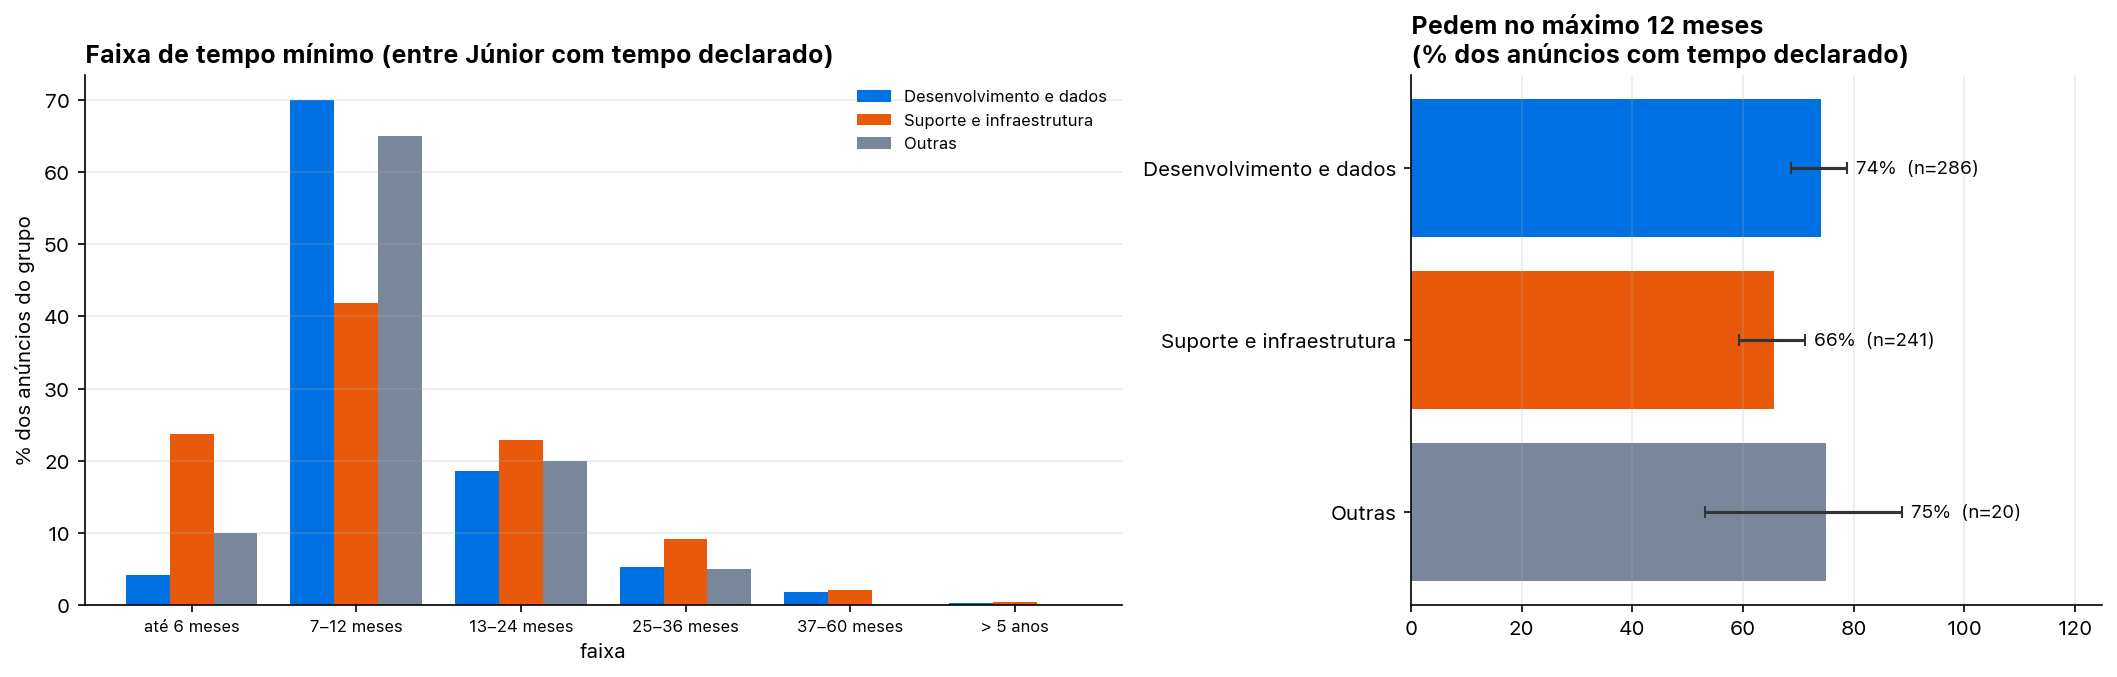

Júnior com tempo mínimo explícito: 547 de 7,021 (7.8%)


In [5]:
tm = df[(df["nivel"] == "Júnior") & df["exp_meses_min"].notna()].copy()
faixas = [0, 6, 12, 24, 36, 60, 121]
rot = ["até 6 meses", "7–12 meses", "13–24 meses", "25–36 meses", "37–60 meses", "> 5 anos"]
tm["faixa"] = pd.cut(tm["exp_meses_min"], bins=faixas, labels=rot, include_lowest=True)
ft = tm.groupby(["grupo", "faixa"], observed=True).size().unstack(fill_value=0).reindex(index=L.ORDEM_GRUPOS, columns=rot, fill_value=0)
fp = ft.div(ft.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
fp.T.plot(kind="bar", ax=axes[0], color=[L.PALETA[g] for g in fp.index], width=.8)
axes[0].set_title("Faixa de tempo mínimo (entre Júnior com tempo declarado)"); axes[0].set_ylabel("% dos anúncios do grupo")
axes[0].set_xticklabels(rot, rotation=0, fontsize=8); axes[0].legend(title="", fontsize=8); axes[0].grid(axis="x", visible=False)
tm["ate12"] = tm["exp_meses_min"] <= 12
tt = L.tabela_prop(tm, "ate12", ["grupo"]).set_index("grupo").reindex(L.ORDEM_GRUPOS)
axes[1].barh(tt.index[::-1], tt["pct"][::-1], color=[L.PALETA[g] for g in tt.index[::-1]],
             xerr=[(tt["pct"] - tt["ic_lo"])[::-1], (tt["ic_hi"] - tt["pct"])[::-1]], error_kw=dict(ecolor="#333", capsize=3))
for i, (g, r) in enumerate(tt[::-1].iterrows()): axes[1].text(r["ic_hi"] + 1.5, i, f"{r['pct']:.0f}%  (n={int(r['n'])})", va="center", fontsize=9)
axes[1].set_title("Pedem no máximo 12 meses\n(% dos anúncios com tempo declarado)"); axes[1].set_xlim(0, 125); axes[1].grid(axis="y", visible=False)
print("Mediana do tempo mínimo (meses) por grupo:", tm.groupby("grupo")["exp_meses_min"].median().reindex(L.ORDEM_GRUPOS).to_dict())
L.salvar(fig, "01_tempo_minimo"); plt.show()
print(f"Júnior com tempo mínimo explícito: {len(tm):,} de {(df['nivel']=='Júnior').sum():,} ({len(tm)/(df['nivel']=='Júnior').sum():.1%})")

## 5. Heterogeneidade por área (Júnior)

O agrupamento em três blocos pode esconder diferenças entre áreas. Abaixo, cada área com pelo menos 50 anúncios de Júnior.

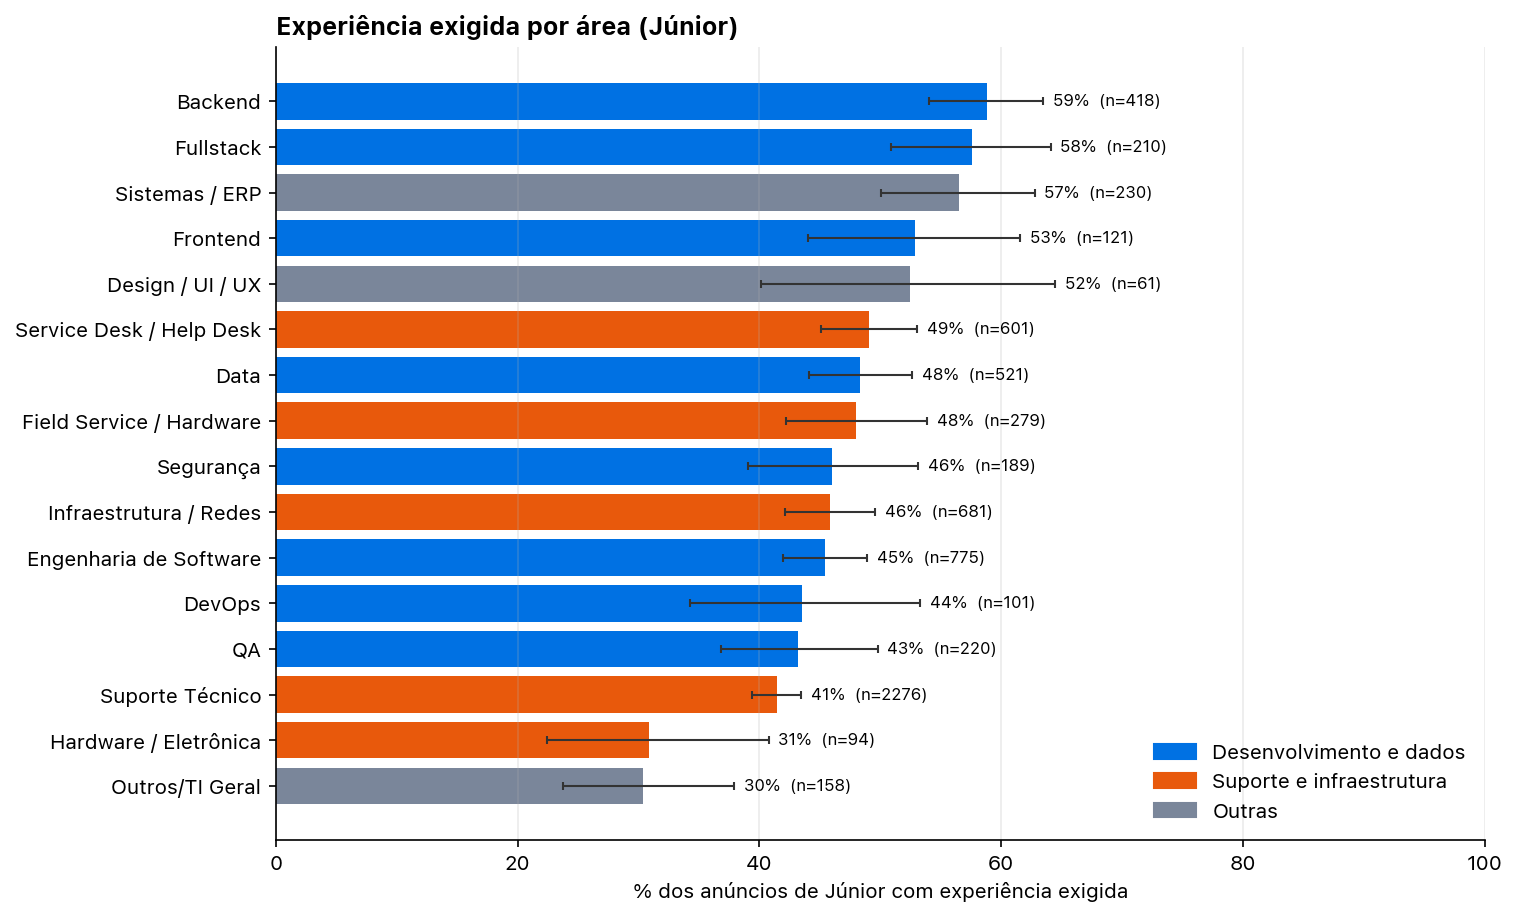

In [6]:
j = df[df["nivel"] == "Júnior"]
ta = L.tabela_prop(j, "exp_obrigatoria", ["area"]); ta = ta[ta["n"] >= 50].sort_values("pct")
cor = [L.PALETA[L.grupo_da_area(a)] for a in ta["area"]]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(ta["area"].astype(str), ta["pct"], color=cor, xerr=[ta["pct"] - ta["ic_lo"], ta["ic_hi"] - ta["pct"]], error_kw=dict(ecolor="#333", lw=1, capsize=2))
for i, (_, r) in enumerate(ta.iterrows()): ax.text(r["ic_hi"] + .8, i, f"{r['pct']:.0f}%  (n={int(r['n'])})", va="center", fontsize=8)
ax.set_xlim(0, 100); ax.set_xlabel("% dos anúncios de Júnior com experiência exigida"); ax.set_title("Experiência exigida por área (Júnior)")
ax.grid(axis="y", visible=False)
import matplotlib.patches as mp
ax.legend(handles=[mp.Patch(color=L.PALETA[g], label=g) for g in L.ORDEM_GRUPOS], loc="lower right")
L.salvar(fig, "01_experiencia_por_area"); plt.show()

## 6. Formação declarada

Categorias **não excludentes** (um anúncio pode citar *cursando superior* e *técnico*). *Cursando* inclui expressões como
"a partir do 3º período". "Técnico em..." pode capturar o nome do cargo, então a coluna *técnico* é a mais ruidosa.

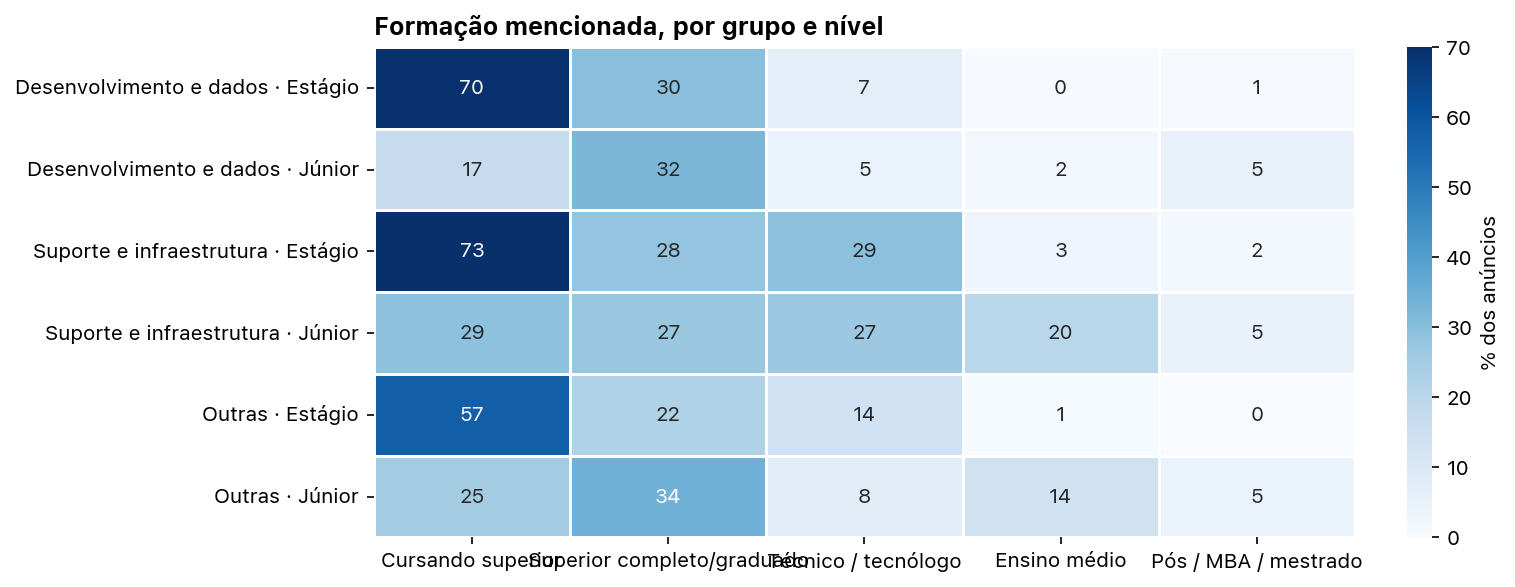

In [7]:
cols = {"f_cursando_superior": "Cursando superior", "f_superior_completo": "Superior completo/graduado",
        "f_tecnico": "Técnico / tecnólogo", "f_medio": "Ensino médio", "f_pos": "Pós / MBA / mestrado"}
f = ej.groupby(["grupo", "nivel"])[list(cols)].mean().mul(100).rename(columns=cols).reindex(
    pd.MultiIndex.from_product([L.ORDEM_GRUPOS, L.NIVEIS_PRINCIPAIS]))
f.index = [f"{g} · {nv}" for g, nv in f.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(f, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% dos anúncios"}, ax=ax, linewidths=.5, vmin=0, vmax=70)
ax.set_title("Formação mencionada, por grupo e nível"); ax.set_ylabel(""); ax.grid(False)
L.salvar(fig, "01_formacao"); plt.show()

## 7. Tabela-resumo (Estágio e Júnior)

In [8]:
def linha(sub):
    n = len(sub)
    out = {"n": n}
    for k, r in {"exp_qualquer": "Qualquer menção", "exp_obrigatoria": "Exigida", "exp_so_desejavel": "Só desejável",
                 "exp_nao_exige": "Diz não exigir", "exp_tempo": "Tempo mínimo declarado"}.items():
        x, lo, hi = L.prop_ic(sub[k].sum(), n)
        out[r] = f"{x:.1f}% [{lo:.1f}–{hi:.1f}]"
    return pd.Series(out)

res = ej.groupby(["grupo", "nivel"]).apply(linha).reindex(pd.MultiIndex.from_product([L.ORDEM_GRUPOS, L.NIVEIS_PRINCIPAIS]))
display(res.style.set_caption("Experiência: % [IC 95% de Wilson]"))
res.to_csv(L.BASE / "tabela_01_experiencia.csv")

## 8. Validação por amostragem

As regras são heurísticas. Abaixo, 6 trechos aleatórios de cada tipo para conferir **a olho** se a detecção faz sentido.
O ideal é que as duas pesquisadoras classifiquem uma amostra maior (como já previsto para o dicionário em `[P11]`).

In [9]:
import re
def primeiro_trecho(tf, texto, rx):
    m = rx.search(tf)
    return L.trecho(texto, m.start(), m.end(), 110) if m else ""

rng = np.random.default_rng(11)
linhas = []
for nome, rx, flag in (("Tempo mínimo", L.EXP_TEMPO, "exp_tempo"), ("Experiência prévia", L.EXP_PREVIA, "exp_previa"),
                       ("Não exige", L.EXP_NAO_EXIGE, "exp_nao_exige")):
    s = df[df[flag]].sample(6, random_state=int(rng.integers(1e6)))
    for _, r in s.iterrows():
        linhas.append({"Tipo": nome, "Nível": r["nivel"], "Área": r["area"], "Trecho": primeiro_trecho(r["tf"], r["texto"], rx)})
display(pd.DataFrame(linhas).style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "11px"}))

Tipo,Nível,Área,Trecho
Tempo mínimo,Júnior,Infraestrutura / Redes,…stacoes de trabalho e servidoresEnsino Superior Completo Requisitos e qualificações Requisitos necessários: ¿ Experiência mínima de 1 ano com suporte (local e remoto). ¿ Experiência em suporte à usuários em equipamentos de videoconferência e impre…
Tempo mínimo,Júnior,Service Desk / Help Desk,…rior na área de TIC ou ter concluído curso técnico profissionalizante nesta área. EXPERIÊNCIA PROFISSIONAL: - 1 (um) ano de experiência na área de TIC em atividade de suporte técnico e/ou help desk ou equivalente; e 1 (um) ano de experiência na…
Tempo mínimo,Júnior,Infraestrutura / Redes,"…, Automação ou Telecomunicações. Registro ativo e regular no CFT (Conselho Federal dos Técnicos Industriais). Experiência mínima de 2 anos em serviços de cabeamento estruturado. CNH categoria B. Conhecimento em infraestrutura de redes e telecomunic…"
Tempo mínimo,Júnior,Backend,"…s do time, contribuindo com o desenvolvimento de projetos e a dinâmica da equipe. O que estamos procurando: - 1+ ano de experiência com Java. - Boa compreensão sobre estruturas básicas de algoritmo e dados. - Conhecimento básico sobre sistem…"
Tempo mínimo,Júnior,Fullstack,Requisitos 2+ anos de experiência na carreira HTML e CSS Apis Restful Spring Boot Kubit Java 17 React Git Conhecimentos Desejáveis MongoDB e Fl…
Tempo mínimo,Júnior,Engenharia de Software,"…PCM visando identificação e tratamento de desvios, bem como oportunidades de melhorias. Outros requisitos : • Experiência de no mínimo 2 anos na área de Manutenção/PCM; • Nível Superior em Engenharia, Administração, Gestão Empresarial, Logística e afi…"
Experiência prévia,Júnior,Infraestrutura / Redes,…r no período da noite Disponibilidade para deslocamento até a estação definida para trabalho Não é necessário ter experiência a empresa disponibilizará cursos capacitantes para exercer as atividades Por que essa vaga é especial: Voc…
Experiência prévia,Júnior,Suporte Técnico,"…ou Salesforce Service Cloud; Noções de processos fiscais, contábeis ou emissão de notas fiscais eletrônicas; Experiência prévia em atendimento ao cliente ou suporte técnico; Vivência em ambientes de tecnologia e SaaS; Conhecimento básico…"
Experiência prévia,Estágio,Suporte Técnico,"…de para estagiar conforme a jornada definida pela empresa. Conhecimentos básicos de informática. Diferenciais Experiência prévia, acadêmica ou profissional, com suporte técnico. Conhecimento em Windows, Microsoft 365, Active Directory ou…"
Experiência prévia,Júnior,Suporte Técnico,"…hecimento do Pacote Office; Boa comunicação oral e escrita; Organização e atenção aos detalhes. Diferencial : experiência anterior em Recursos Humanos, integração, atendimento interno ou rotinas administrativas de RH. Show more Show less"


## 9. Números para o texto (gerados automaticamente)

In [10]:
def pct(sub, col): return 100 * sub[col].mean()
d_e = df[(df.grupo == L.G_DEV) & (df.nivel == "Estágio")]; d_j = df[(df.grupo == L.G_DEV) & (df.nivel == "Júnior")]
s_e = df[(df.grupo == L.G_SUP) & (df.nivel == "Estágio")]; s_j = df[(df.grupo == L.G_SUP) & (df.nivel == "Júnior")]
Markdown(f"""
- Em **Desenvolvimento e dados**, {pct(d_j,'exp_qualquer'):.0f}% dos anúncios de **Júnior** mencionam alguma exigência de experiência (exigida: {pct(d_j,'exp_obrigatoria'):.0f}%), contra {pct(d_e,'exp_qualquer'):.0f}% dos de **Estágio** (n = {len(d_j):,} e {len(d_e):,}).
- Em **Suporte e infraestrutura**, os valores são {pct(s_j,'exp_qualquer'):.0f}% (Júnior) e {pct(s_e,'exp_qualquer'):.0f}% (Estágio).
- Apenas {pct(df,'exp_nao_exige'):.1f}% de todos os anúncios afirmam não exigir experiência; entre os de Júnior, {pct(df[df.nivel=='Júnior'],'exp_nao_exige'):.1f}%.
- Entre os {len(tm):,} anúncios de Júnior com tempo declarado, a mediana do tempo mínimo é de **{tm['exp_meses_min'].median():.0f} meses**.
""")


- Em **Desenvolvimento e dados**, 61% dos anúncios de **Júnior** mencionam alguma exigência de experiência (exigida: 49%), contra 19% dos de **Estágio** (n = 2,641 e 1,090).
- Em **Suporte e infraestrutura**, os valores são 55% (Júnior) e 14% (Estágio).
- Apenas 2.5% de todos os anúncios afirmam não exigir experiência; entre os de Júnior, 1.6%.
- Entre os 547 anúncios de Júnior com tempo declarado, a mediana do tempo mínimo é de **12 meses**.


### Como interpretar
- A diferença Estágio × Júnior é **esperada** pela natureza dos cargos; não prova mudança nem efeito da IA.
- O artigo pode usar este resultado para **descrever** a barreira de experiência no nível Júnior e dialogar com Westby et al. (2026) e Dobslaw et al. (2023), sem afirmar tendência.
- Menções a "experiência com tecnologia" misturam exigência de domínio técnico com exigência de vivência profissional; vale reportar os tipos separadamente.
- **Ponto para a orientadora:** a heurística *obrigatória × desejável* e a separação entre os três tipos devem constar na Seção 3.4 se forem usadas.